In [1]:
import sys
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
print("Python version:")
print(sys.version)

print("\nScanpy version:")
print(sc.__version__)

print("\nPandas version:")
print(pd.__version__)

Python version:
3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]

Scanpy version:
1.12.4

Pandas version:
3.0.6


C:\Users\strangers\AppData\Local\Temp\ipykernel_20808\833510663.py:5: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(sc.__version__)


In [3]:
from pathlib import Path
import gzip

metadata_file = Path("../data/metadata/GSE221156_series_matrix.txt.gz")

print("File exists:", metadata_file.exists())
print("File path:", metadata_file)

File exists: True
File path: ..\data\metadata\GSE221156_series_matrix.txt.gz


In [4]:
with gzip.open(metadata_file, "rt") as f:
    lines = f.readlines()

print("Number of lines:", len(lines))

for line in lines[:20]:
    print(line.strip())

Number of lines: 97
!Series_title	"Dissecting cell-type specific pathophysiological changes in human type-2 diabetic pancreatic islets using single-cell transcriptomic data"
!Series_geo_accession	"GSE221156"
!Series_status	"Public on Mar 30 2023"
!Series_submission_date	"Dec 16 2022"
!Series_last_update_date	"Aug 21 2026"
!Series_pubmed_id	"41986506"
!Series_summary	"Pancreatic islet (dys)function is central to glucose homeostasis and type 2 diabetes (patho)physiology. Human islets consist of multiple endocrine (alpha, beta, delta, gamma), endothelial, and resident/inflitrating immune cells whose coordinated functions modulate glucose mobilization or disposal. Single cell transcriptome profiling (scRNA-seq) studies have been applied to dissect human islet cellular heterogeneity, identify islet cell (sub)populations, and define their molecular repertoire. However, precise understanding of cell type-specific alterations in type 2 diabetic vs. non-diabetic individuals is lacking, due in p

In [5]:
for line in lines:
    if line.startswith("!Sample_"):
        print(line.strip())

!Sample_title	"Islet28"	"Islet29"	"Islet30"	"Islet31"	"Islet32"	"Islet33"	"Islet34"	"Islet37"	"Islet38"	"Islet39"	"Islet40"	"Islet41"	"Islet42"	"Islet44"	"Islet45"	"Islet47"	"Islet48"	"Islet47/48_MS19006"	"Islet47/48_MS19007"	"Islet50"	"Islet52"	"Islet53"	"Islet54"	"Islet55"	"Islet56"	"Islet57"	"Islet58"	"Islet57/58_MS19016"	"Islet57/58_MS19017"	"Islet59"	"Islet60"	"Islet59/60_MS19020"	"Islet59/60_MS19021"	"Islet61"	"Islet62"	"Islet63"	"Islet68"	"Islet70/71_MS19034"	"Islet70/71_MS19035"	"Islet73"	"Islet80"	"Islet84/85_MS19042"	"Islet84/85_MS19043"	"Islet89"	"Islet91"	"Islet101"	"Islet104"	"Islet107"	"Islet118/119_MS20086"	"Islet118/119_MS20087"	"Islet123"	"Islet126"	"Islet127"	"Islet128"
!Sample_geo_accession	"GSM6846488"	"GSM6846489"	"GSM6846490"	"GSM6846491"	"GSM6846492"	"GSM6846493"	"GSM6846494"	"GSM6846495"	"GSM6846496"	"GSM6846497"	"GSM6846498"	"GSM6846499"	"GSM6846500"	"GSM6846501"	"GSM6846502"	"GSM6846503"	"GSM6846504"	"GSM6846505"	"GSM6846506"	"GSM6846507"	"GSM6846508"	"GSM6846

In [6]:
print(line.strip())

!series_matrix_table_end


In [7]:
for line in lines:
    if line.startswith("!Sample_"):
        print(line.strip())

!Sample_title	"Islet28"	"Islet29"	"Islet30"	"Islet31"	"Islet32"	"Islet33"	"Islet34"	"Islet37"	"Islet38"	"Islet39"	"Islet40"	"Islet41"	"Islet42"	"Islet44"	"Islet45"	"Islet47"	"Islet48"	"Islet47/48_MS19006"	"Islet47/48_MS19007"	"Islet50"	"Islet52"	"Islet53"	"Islet54"	"Islet55"	"Islet56"	"Islet57"	"Islet58"	"Islet57/58_MS19016"	"Islet57/58_MS19017"	"Islet59"	"Islet60"	"Islet59/60_MS19020"	"Islet59/60_MS19021"	"Islet61"	"Islet62"	"Islet63"	"Islet68"	"Islet70/71_MS19034"	"Islet70/71_MS19035"	"Islet73"	"Islet80"	"Islet84/85_MS19042"	"Islet84/85_MS19043"	"Islet89"	"Islet91"	"Islet101"	"Islet104"	"Islet107"	"Islet118/119_MS20086"	"Islet118/119_MS20087"	"Islet123"	"Islet126"	"Islet127"	"Islet128"
!Sample_geo_accession	"GSM6846488"	"GSM6846489"	"GSM6846490"	"GSM6846491"	"GSM6846492"	"GSM6846493"	"GSM6846494"	"GSM6846495"	"GSM6846496"	"GSM6846497"	"GSM6846498"	"GSM6846499"	"GSM6846500"	"GSM6846501"	"GSM6846502"	"GSM6846503"	"GSM6846504"	"GSM6846505"	"GSM6846506"	"GSM6846507"	"GSM6846508"	"GSM6846

In [8]:
records = []

# Find the sample IDs and sample titles
geo_line = next(line for line in lines if line.startswith("!Sample_geo_accession"))
title_line = next(line for line in lines if line.startswith("!Sample_title"))

geo_ids = [x.strip('"') for x in geo_line.strip().split("\t")[1:]]
titles = [x.strip('"') for x in title_line.strip().split("\t")[1:]]

# Create one record for each sample
for gsm, title in zip(geo_ids, titles):
    records.append({
        "GSM": gsm,
        "sample_title": title
    })

# Add all the sample characteristics
for line in lines:
    if line.startswith("!Sample_characteristics_ch1"):
        values = [x.strip('"') for x in line.strip().split("\t")[1:]]

        for i, value in enumerate(values):
            if ": " in value:
                key, val = value.split(": ", 1)

                # Clean column names
                key = key.strip().lower().replace(" ", "_")

                records[i][key] = val.strip()

metadata_df = pd.DataFrame(records)

metadata_df.head()

,GSM,sample_title,tissue,treatment,chemistry,disease_state,sex,bmi,race,hba1c,age,center,cause_of_death,library_id
0,GSM6846488,Islet28,Pancreatic islets,None,V2,Type2Diabetic,Male,35.6,Hispanic,7.1,51,Scharp-Lacy,Cerebrovascular/stroke,MS17001
1,GSM6846489,Islet29,Pancreatic islets,None,V2,NonDiabetic,Male,35.6,White,5.1,54,Wisconsin,Cerebrovascular/stroke,MS17002
2,GSM6846490,Islet30,Pancreatic islets,None,V2,Type2Diabetic,Female,42.8,Hispanic,6.6,52,Scharp-Lacy,Cerebrovascular/stroke,MS17003
3,GSM6846491,Islet31,Pancreatic islets,None,V2,Type2Diabetic,Male,27.7,Hispanic,6.5,59,Scharp-Lacy,Cerebrovascular/stroke,MS17004
4,GSM6846492,Islet32,Pancreatic islets,None,V2,Type2Diabetic,Male,27.7,White,6.3,35,Scharp-Lacy,Cerebrovascular/stroke,MS17005


In [9]:
print("Number of samples:", metadata_df.shape[0])
print("Number of columns:", metadata_df.shape[1])

print("\nDisease-state counts:")
print(metadata_df["disease_state"].value_counts(dropna=False))

Number of samples: 54
Number of columns: 14

Disease-state counts:
disease_state
NonDiabetic                  17
Type2Diabetic                14
PreDiabetic                  11
NonDiabetic/Type2Diabetic     4
PreDiabetic/Type2Diabetic     4
NonDiabetic/PreDiabetic       2
Type2Diabetic/PreDiabetic     2
Name: count, dtype: int64


In [10]:
metadata_df[["GSM", "sample_title", "disease_state", "sex", "bmi"]].head(10)

,GSM,sample_title,disease_state,sex,bmi
0,GSM6846488,Islet28,Type2Diabetic,Male,35.6
1,GSM6846489,Islet29,NonDiabetic,Male,35.6
2,GSM6846490,Islet30,Type2Diabetic,Female,42.8
3,GSM6846491,Islet31,Type2Diabetic,Male,27.7
4,GSM6846492,Islet32,Type2Diabetic,Male,27.7
5,GSM6846493,Islet33,Type2Diabetic,Female,38.1
6,GSM6846494,Islet34,NonDiabetic,Male,25.3
7,GSM6846495,Islet37,NonDiabetic,Male,28.5
8,GSM6846496,Islet38,NonDiabetic,Male,27.3
9,GSM6846497,Islet39,Type2Diabetic,Female,35.4


In [11]:
print("Total GEO samples:", len(metadata_df))

print("\nUnique sample titles:")
print(metadata_df["sample_title"].nunique())

print("\nDuplicate sample titles:")
print(metadata_df["sample_title"].duplicated().sum())

Total GEO samples: 54

Unique sample titles:
54

Duplicate sample titles:
0


In [12]:
duplicates = metadata_df[
    metadata_df["sample_title"].duplicated(keep=False)
].sort_values("sample_title")

duplicates[["GSM", "sample_title", "disease_state", "sex", "bmi"]]

,GSM,sample_title,disease_state,sex,bmi


In [13]:
print("All metadata columns:")
for col in metadata_df.columns:
    print(col)

All metadata columns:
GSM
sample_title
tissue
treatment
chemistry
disease_state
sex
bmi
race
hba1c
age
center
cause_of_death
library_id


In [14]:
candidate_cols = [
    col for col in metadata_df.columns
    if any(word in col.lower() for word in
           ["donor", "subject", "individual", "library", "sample"])
]

print("Possible donor/sample ID columns:")
print(candidate_cols)

Possible donor/sample ID columns:
['sample_title', 'library_id']


In [15]:
metadata_df[[
    "GSM",
    "sample_title",
    "library_id",
    "disease_state",
    "sex",
    "bmi"
]].head(20)

,GSM,sample_title,library_id,disease_state,sex,bmi
0,GSM6846488,Islet28,MS17001,Type2Diabetic,Male,35.6
1,GSM6846489,Islet29,MS17002,NonDiabetic,Male,35.6
2,GSM6846490,Islet30,MS17003,Type2Diabetic,Female,42.8
3,GSM6846491,Islet31,MS17004,Type2Diabetic,Male,27.7
4,GSM6846492,Islet32,MS17005,Type2Diabetic,Male,27.7
5,GSM6846493,Islet33,MS17006,Type2Diabetic,Female,38.1
6,GSM6846494,Islet34,MS18001,NonDiabetic,Male,25.3
7,GSM6846495,Islet37,MS18002,NonDiabetic,Male,28.5
8,GSM6846496,Islet38,MS18003,NonDiabetic,Male,27.3
9,GSM6846497,Islet39,MS18004,Type2Diabetic,Female,35.4


In [16]:
print("Total GEO samples:", len(metadata_df))
print("Unique sample titles:", metadata_df["sample_title"].nunique())
print("Unique library IDs:", metadata_df["library_id"].nunique())

print("\nMost common library IDs:")
print(metadata_df["library_id"].value_counts().head(15))

Total GEO samples: 54
Unique sample titles: 54
Unique library IDs: 54

Most common library IDs:
library_id
MS17001    1
MS17002    1
MS17003    1
MS17004    1
MS17005    1
MS17006    1
MS18001    1
MS18002    1
MS18003    1
MS18004    1
MS18005    1
MS18006    1
MS19001    1
MS19002    1
MS19003    1
Name: count, dtype: int64


In [17]:
import pyreadr
from pathlib import Path

beta_rds = Path("../data/processed/Rmarkdown/BetaPseudobulk.rds")

print("File exists:", beta_rds.exists())
print("File size (MB):", round(beta_rds.stat().st_size / (1024**2), 2))

File exists: True
File size (MB): 2.03


In [18]:
result = pyreadr.read_r(beta_rds)

print("Objects found inside the RDS file:")
print(result.keys())

Objects found inside the RDS file:
odict_keys([])


In [1]:
import pandas as pd

beta_counts = pd.read_csv(
    "../data/processed/beta_counts.csv",
    index_col=0
)

beta_design = pd.read_csv(
    "../data/processed/beta_design.csv",
    index_col=0
)

print("Beta counts shape:", beta_counts.shape)
print("Beta design shape:", beta_design.shape)

print("\nDisease groups:")
print(beta_design["Condition"].value_counts())

print("\nFirst donor IDs in counts:")
print(beta_counts.columns[:6].tolist())

print("\nFirst donor IDs in metadata:")
print(beta_design.index[:6].tolist())

print(
    "\nSame donor order:",
    beta_counts.columns.tolist() == beta_design.index.tolist()
)

Beta counts shape: (27739, 48)
Beta design shape: (48, 8)

Disease groups:
Condition
ND     17
T2D    17
PD     14
Name: count, dtype: int64

First donor IDs in counts:
['Islet104', 'Islet107', 'Islet123', 'Islet29', 'Islet34', 'Islet37']

First donor IDs in metadata:
['Islet104', 'Islet107', 'Islet123', 'Islet29', 'Islet34', 'Islet37']

Same donor order: True


In [2]:
# Keep only Non-Diabetic (ND) and Type 2 Diabetic (T2D) donors
analysis_design = beta_design[
    beta_design["Condition"].isin(["ND", "T2D"])
].copy()

# Keep the matching columns from the expression matrix
analysis_counts = beta_counts[
    analysis_design.index
].copy()

print("Analysis counts shape:", analysis_counts.shape)
print("Analysis metadata shape:", analysis_design.shape)

print("\nDisease groups used for analysis:")
print(analysis_design["Condition"].value_counts())

print("\nDonor order still matched:")
print(
    analysis_counts.columns.tolist()
    == analysis_design.index.tolist()
)

Analysis counts shape: (27739, 34)
Analysis metadata shape: (34, 8)

Disease groups used for analysis:
Condition
ND     17
T2D    17
Name: count, dtype: int64

Donor order still matched:
True


In [3]:
# Filter out very low-expression genes
# Keep genes with at least 10 counts in at least 5 donors

min_count = 10
min_donors = 5

keep_genes = (analysis_counts >= min_count).sum(axis=1) >= min_donors

filtered_counts = analysis_counts.loc[keep_genes].copy()

print("Genes before filtering:", analysis_counts.shape[0])
print("Genes after filtering:", filtered_counts.shape[0])
print("Genes removed:", analysis_counts.shape[0] - filtered_counts.shape[0])

print("\nFiltered matrix shape:")
print(filtered_counts.shape)

Genes before filtering: 27739
Genes after filtering: 17408
Genes removed: 10331

Filtered matrix shape:
(17408, 34)


In [4]:
# Total pseudobulk counts for each donor
library_sizes = filtered_counts.sum(axis=0)

library_summary = pd.DataFrame({
    "library_size": library_sizes,
    "Condition": analysis_design["Condition"],
    "Chemistry": analysis_design["Chemistry"],
    "Ncells": analysis_design["Ncells"]
})

print("Library-size summary:")
print(library_sizes.describe())

print("\nMean library size by disease group:")
print(library_summary.groupby("Condition")["library_size"].mean())

print("\nMean library size by chemistry:")
print(library_summary.groupby("Chemistry")["library_size"].mean())

print("\nCorrelation between library size and number of beta cells:")
print(
    library_summary[["library_size", "Ncells"]]
    .corr()
)

Library-size summary:
count    3.400000e+01
mean     4.035965e+07
std      2.154928e+07
min      1.263217e+07
25%      2.301163e+07
50%      3.885497e+07
75%      5.229115e+07
max      9.626387e+07
dtype: float64

Mean library size by disease group:
Condition
ND     4.998126e+07
T2D    3.073804e+07
Name: library_size, dtype: float64

Mean library size by chemistry:
Chemistry
V2    2.359229e+07
V3    4.837882e+07
Name: library_size, dtype: float64

Correlation between library size and number of beta cells:
              library_size    Ncells
library_size      1.000000  0.849137
Ncells            0.849137  1.000000


In [5]:
import numpy as np

# Library size for each donor after gene filtering
library_sizes = filtered_counts.sum(axis=0)

# Convert raw counts to counts per million (CPM)
cpm = filtered_counts.divide(library_sizes, axis=1) * 1_000_000

# Log2 transform
log_cpm = np.log2(cpm + 1)

print("Normalized matrix shape:", log_cpm.shape)

print("\nCPM library sums:")
print(cpm.sum(axis=0).describe())

print("\nLog-CPM summary:")
print(log_cpm.stack().describe())

Normalized matrix shape: (17408, 34)

CPM library sums:
count    3.400000e+01
mean     1.000000e+06
std      6.721242e-11
min      1.000000e+06
25%      1.000000e+06
50%      1.000000e+06
75%      1.000000e+06
max      1.000000e+06
dtype: float64

Log-CPM summary:
count    591872.000000
mean          2.856069
std           2.131547
min           0.000000
25%           0.967727
50%           2.671096
75%           4.239675
max          18.578407
dtype: float64


In [6]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Transpose so rows = donors, columns = genes
X = log_cpm.T

# Standardize genes before PCA
X_scaled = StandardScaler().fit_transform(X)

# Run PCA
pca = PCA(n_components=5)
pcs = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    pcs,
    index=analysis_design.index,
    columns=[f"PC{i+1}" for i in range(5)]
)

pca_df["Condition"] = analysis_design["Condition"]
pca_df["Chemistry"] = analysis_design["Chemistry"]
pca_df["Ncells"] = analysis_design["Ncells"]

print("Explained variance ratio:")
for i, v in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"PC{i}: {v:.4f}")

print("\nPCA table preview:")
print(pca_df.head())

Explained variance ratio:
PC1: 0.2393
PC2: 0.1269
PC3: 0.0836
PC4: 0.0509
PC5: 0.0460

PCA table preview:
                PC1        PC2        PC3        PC4        PC5 Condition  \
Islet104 -47.376158  18.537476 -16.964609   8.651117  -0.503249        ND   
Islet107 -87.061923 -69.008648 -40.769279  18.766106 -12.101936        ND   
Islet123 -33.039074 -18.742379   5.118453  31.056099 -28.342634        ND   
Islet29   57.937083 -25.950579  82.472119 -11.292112  54.208151        ND   
Islet34   64.264169 -58.296339 -41.723787  14.017619  -6.764778        ND   

         Chemistry  Ncells  
Islet104        V3    2566  
Islet107        V3    2988  
Islet123        V3    2912  
Islet29         V2    1089  
Islet34         V2    2732  


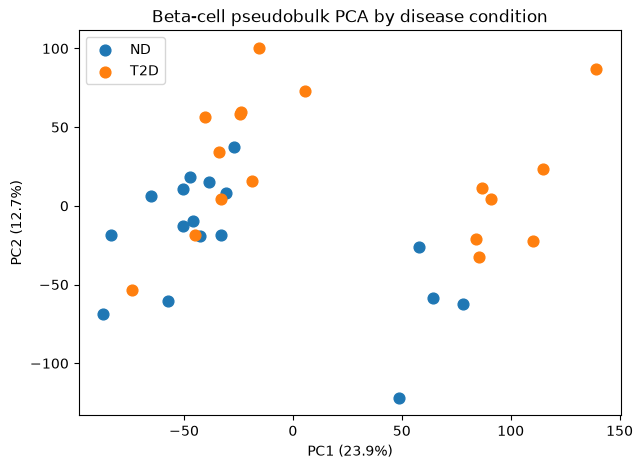

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))

for condition in pca_df["Condition"].unique():
    subset = pca_df[pca_df["Condition"] == condition]
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        label=condition,
        s=60
    )

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Beta-cell pseudobulk PCA by disease condition")
ax.legend()
plt.show()

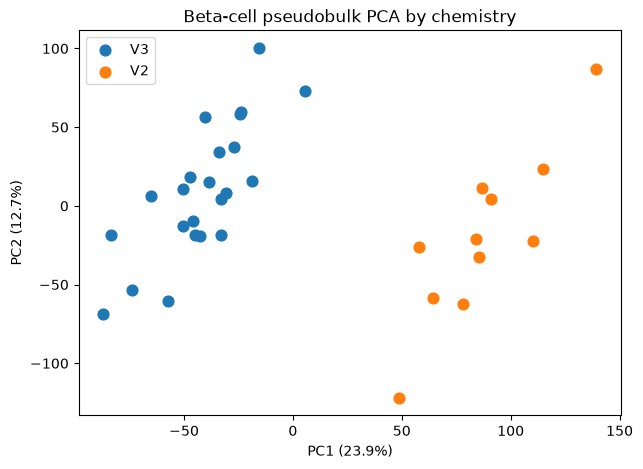

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))

for chemistry in pca_df["Chemistry"].unique():
    subset = pca_df[pca_df["Chemistry"] == chemistry]
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        label=chemistry,
        s=60
    )

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Beta-cell pseudobulk PCA by chemistry")
ax.legend()
plt.show()

In [9]:
# Check whether disease condition is associated with sequencing chemistry
condition_chemistry = pd.crosstab(
    analysis_design["Condition"],
    analysis_design["Chemistry"],
    margins=True
)

print("Condition vs Chemistry:")
print(condition_chemistry)

print("\nColumn-normalized proportions:")
print(
    pd.crosstab(
        analysis_design["Condition"],
        analysis_design["Chemistry"],
        normalize="columns"
    ).round(3)
)

Condition vs Chemistry:
Chemistry  V2  V3  All
Condition             
ND          4  13   17
T2D         7  10   17
All        11  23   34

Column-normalized proportions:
Chemistry     V2     V3
Condition              
ND         0.364  0.565
T2D        0.636  0.435


In [10]:
from scipy.stats import fisher_exact

table = pd.crosstab(
    analysis_design["Condition"],
    analysis_design["Chemistry"]
)

odds_ratio, p_value = fisher_exact(table)

print("Condition vs Chemistry contingency table:")
print(table)

print("\nFisher's exact test")
print("Odds ratio:", odds_ratio)
print("p-value:", p_value)

Condition vs Chemistry contingency table:
Chemistry  V2  V3
Condition        
ND          4  13
T2D         7  10

Fisher's exact test
Odds ratio: 0.43956043956043955
p-value: 0.4646397231491781


In [11]:
de_results = pd.read_csv(
    "../results/tables/beta_T2D_vs_ND_DESeq2.csv"
)

print("DE result shape:", de_results.shape)

print("\nTop 10 genes by adjusted p-value:")
print(
    de_results[
        ["gene", "log2FoldChange", "pvalue", "padj"]
    ].head(10)
)

print("\nTop 10 upregulated genes in T2D:")
print(
    de_results
    .dropna(subset=["padj"])
    .sort_values("log2FoldChange", ascending=False)
    [["gene", "log2FoldChange", "padj"]]
    .head(10)
)

print("\nTop 10 downregulated genes in T2D:")
print(
    de_results
    .dropna(subset=["padj"])
    .sort_values("log2FoldChange", ascending=True)
    [["gene", "log2FoldChange", "padj"]]
    .head(10)
)

DE result shape: (17408, 7)

Top 10 genes by adjusted p-value:
       gene  log2FoldChange        pvalue          padj
0  TBX2-AS1        5.167929  2.069078e-21  3.600816e-17
1    PHLDB2       -0.788749  6.366154e-20  5.539509e-16
2     PDE4B        1.580121  6.528633e-18  3.312518e-14
3     ELFN1        4.225144  9.517090e-18  3.312518e-14
4     OPLAH        2.393988  7.992564e-18  3.312518e-14
5     OPRD1       -2.066593  3.884085e-16  1.126579e-12
6    KCNAB2        1.163879  6.075587e-16  1.510478e-12
7     TAFA4       -1.729222  1.151485e-15  2.284437e-12
8     FOXA3       -1.276041  1.181402e-15  2.284437e-12
9     FAIM2        4.109868  2.308270e-15  4.017083e-12

Top 10 upregulated genes in T2D:
          gene  log2FoldChange          padj
10        TBX2        5.543451  9.599965e-12
20       BARX1        5.485732  9.819401e-09
0     TBX2-AS1        5.167929  3.600816e-17
416       SIX6        4.560948  2.115846e-03
36       FOXF1        4.433751  1.053049e-07
3        ELFN1   

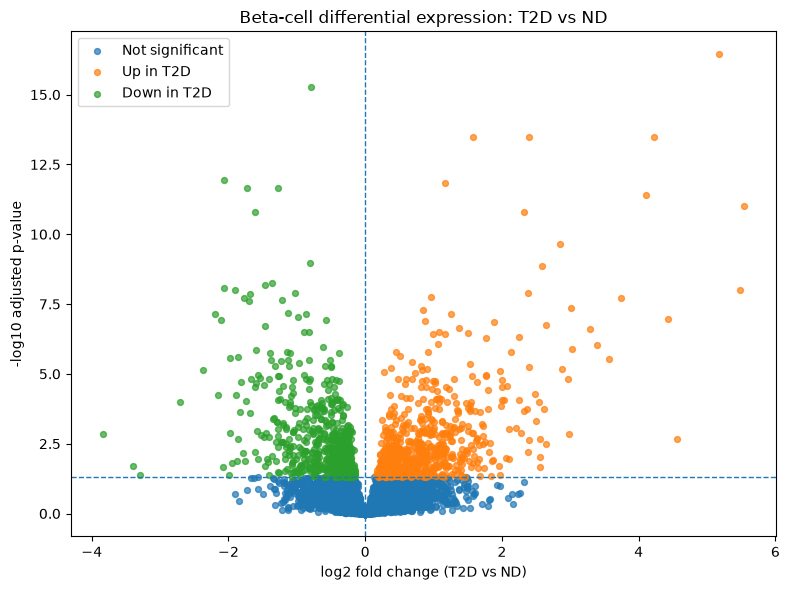

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Remove rows without valid adjusted p-values
volcano = de_results.dropna(
    subset=["padj", "log2FoldChange"]
).copy()

# Avoid taking log10(0)
volcano["padj_plot"] = volcano["padj"].clip(lower=1e-300)

# -log10 adjusted p-value
volcano["minus_log10_padj"] = -np.log10(volcano["padj_plot"])

# Significance categories
volcano["status"] = "Not significant"

volcano.loc[
    (volcano["padj"] < 0.05) &
    (volcano["log2FoldChange"] > 0),
    "status"
] = "Up in T2D"

volcano.loc[
    (volcano["padj"] < 0.05) &
    (volcano["log2FoldChange"] < 0),
    "status"
] = "Down in T2D"

fig, ax = plt.subplots(figsize=(8, 6))

for status in ["Not significant", "Up in T2D", "Down in T2D"]:
    subset = volcano[volcano["status"] == status]

    ax.scatter(
        subset["log2FoldChange"],
        subset["minus_log10_padj"],
        label=status,
        s=18,
        alpha=0.7
    )

ax.axvline(0, linestyle="--", linewidth=1)
ax.axhline(-np.log10(0.05), linestyle="--", linewidth=1)

ax.set_xlabel("log2 fold change (T2D vs ND)")
ax.set_ylabel("-log10 adjusted p-value")
ax.set_title("Beta-cell differential expression: T2D vs ND")
ax.legend()

plt.tight_layout()

# Save figure
Path("../results/figures").mkdir(
    parents=True,
    exist_ok=True
)

plt.savefig(
    "../results/figures/beta_T2D_vs_ND_volcano.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Create significant gene sets for pathway analysis

significant = de_results[
    de_results["padj"].notna() &
    (de_results["padj"] < 0.05)
].copy()

up_genes = significant[
    significant["log2FoldChange"] > 0
].copy()

down_genes = significant[
    significant["log2FoldChange"] < 0
].copy()

print("Total significant genes:", len(significant))
print("Upregulated in T2D:", len(up_genes))
print("Downregulated in T2D:", len(down_genes))

print("\nTop 15 upregulated genes:")
print(
    up_genes
    .sort_values("padj")
    [["gene", "log2FoldChange", "padj"]]
    .head(15)
)

print("\nTop 15 downregulated genes:")
print(
    down_genes
    .sort_values("padj")
    [["gene", "log2FoldChange", "padj"]]
    .head(15)
)

# Save gene lists
significant.to_csv(
    "../results/tables/beta_T2D_vs_ND_significant_genes.csv",
    index=False
)

up_genes[["gene"]].to_csv(
    "../results/tables/beta_T2D_upregulated_genes.csv",
    index=False
)

down_genes[["gene"]].to_csv(
    "../results/tables/beta_T2D_downregulated_genes.csv",
    index=False
)

print("\nGene lists saved.")

Total significant genes: 1334
Upregulated in T2D: 670
Downregulated in T2D: 664

Top 15 upregulated genes:
        gene  log2FoldChange          padj
0   TBX2-AS1        5.167929  3.600816e-17
2      PDE4B        1.580121  3.312518e-14
3      ELFN1        4.225144  3.312518e-14
4      OPLAH        2.393988  3.312518e-14
6     KCNAB2        1.163879  1.510478e-12
9      FAIM2        4.109868  4.017083e-12
10      TBX2        5.543451  9.599965e-12
11  HSD17B13        2.323937  1.533013e-11
13      TSHR        2.852283  2.212528e-10
15      DKK3        2.580657  1.353449e-09
20     BARX1        5.485732  9.819401e-09
21     NHLH2        2.385167  1.243478e-08
24      FGD6        0.963464  1.767762e-08
25   PCOLCE2        3.742922  1.943293e-08
29     CAMK4        3.010976  4.512019e-08

Top 15 downregulated genes:
       gene  log2FoldChange          padj
1    PHLDB2       -0.788749  5.539509e-16
5     OPRD1       -2.066593  1.126579e-12
7     TAFA4       -1.729222  2.284437e-12
8     FO

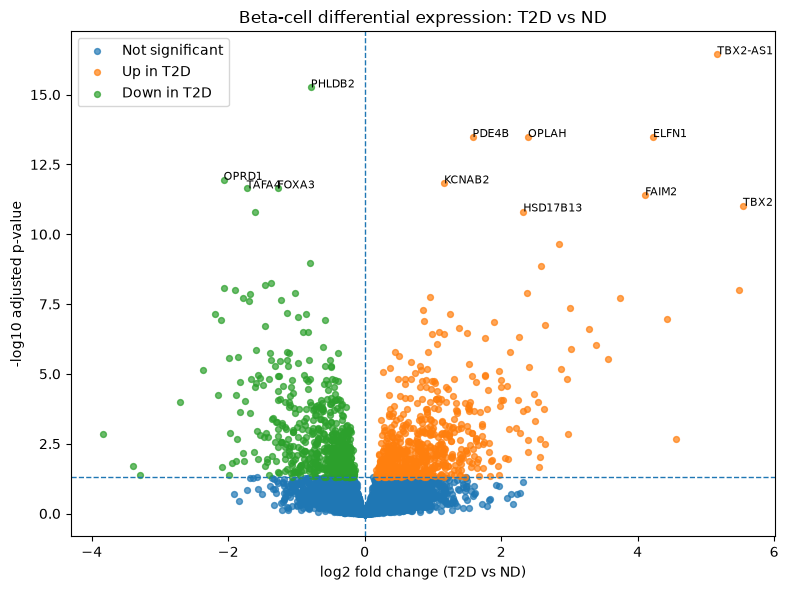

In [14]:
# Label strongest genes on volcano plot

top_labels = (
    volcano
    .sort_values("padj")
    .head(12)
)

fig, ax = plt.subplots(figsize=(8, 6))

for status in ["Not significant", "Up in T2D", "Down in T2D"]:
    subset = volcano[volcano["status"] == status]

    ax.scatter(
        subset["log2FoldChange"],
        subset["minus_log10_padj"],
        label=status,
        s=18,
        alpha=0.7
    )

ax.axvline(0, linestyle="--", linewidth=1)
ax.axhline(-np.log10(0.05), linestyle="--", linewidth=1)

for _, row in top_labels.iterrows():
    ax.text(
        row["log2FoldChange"],
        row["minus_log10_padj"],
        row["gene"],
        fontsize=8
    )

ax.set_xlabel("log2 fold change (T2D vs ND)")
ax.set_ylabel("-log10 adjusted p-value")
ax.set_title("Beta-cell differential expression: T2D vs ND")
ax.legend()

plt.tight_layout()

plt.savefig(
    "../results/figures/beta_T2D_vs_ND_volcano_labeled.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()